# Рынок вакансий Кыргызстана: что предлагают работодатели и что они скрывают

**Анализ 12 646 онлайн-вакансий с hh.kg и lalafo.kg, февраль–март 2024**

Этот ноутбук содержит итоги. Подробные расчёты, тесты и графики находятся в ноутбуках 01–06
(карта в конце).

---

## Вопрос и для кого этот анализ

**Главный вопрос:** от чего зависит предлагаемая зарплата в Кыргызстане и почему половина
работодателей её не указывает?

**Для кого:**
- **соискатели:** чего ожидать, во что вкладываться, как читать объявления;
- **работодатели и HR:** насколько конкурентно предложение и стоит ли указывать зарплату.

**Данные:** открытый датасет School of Data Kyrgyzstan («Кыргызстан в цифрах»), вакансии с hh.kg и lalafo.kg.
После очистки 12 646 вакансий, из них 5 840 с правдоподобной зарплатой.

In [1]:
import pandas as pd
import numpy as np
from IPython.display import Image, display

FIG = "../reports/figures/"
df = pd.read_csv("../data/processed/vacancies_clean.csv")
sal = df[df["has_salary"]]
key = {
    "вакансий": len(df),
    "с зарплатой": len(sal),
    "скрыли зарплату": f"{df['salary_hidden'].mean():.0%}",
    "медиана, сом": f"{sal['salary_kgs'].median():,.0f}",
    "доля Бишкека": f"{(df['city'] == 'Бишкек').mean():.0%}",
    "доля lalafo": f"{(df['source'] == 'lalafo').mean():.0%}",
}
pd.Series(key, name="ключевые цифры").to_frame()

,ключевые цифры
вакансий,12646
с зарплатой,5840
скрыли зарплату,52%
"медиана, сом","39,000"
доля Бишкека,83%
доля lalafo,73%


## Главное за одну минуту

1. **Половина рынка скрывает зарплату (52%).** Это не связано с уровнем оплаты в сфере,
   но связано с опытом и с работодателем: банки на hh скрывают зарплату в 94% вакансий.
2. **Опыт даёт самый большой прирост.** 3–6 лет опыта: +54% к вакансиям без опыта
   (95% интервал: от +44% до +60%).
3. **hh и lalafo это два разных рынка.** На hh офис и продажи, на lalafo сфера услуг и производство.
   hh платит на 14% больше; в IT разница почти втрое (80 000 против 30 000 сом).
4. **Профессия важнее сферы.** Охранник получает около 18 000 сом, технолог около 93 000:
   разница в 5 раз.
5. **Диплом почти не влияет на зарплату.** Высшее образование упоминается в 9% вакансий,
   и внутри одной сферы такие вакансии платят лишь на ~1% больше.
6. **Разрыв по полу в основном объясняется профессиями.** Вакансии «для девушек» на lalafo
   платят на 18% меньше, но внутри одной профессии разница всего 6%.
7. **Зарплаты круглые.** 88% сумм, кратных тысяче, заканчиваются на 0 000 или 5 000.

Типичная зарплата в объявлениях составляет **около 35–40 тыс. сом** (точная цифра зависит
от допущений очистки). В Бишкеке это примерно на 10% выше официальной средней зарплаты.

---
## 1. Половина вакансий скрывает зарплату, чаще всего у опытных и в банках

- 52% вакансий без зарплаты: на lalafo 56%, на hh 41%.
- Чем больше требуется опыта, тем чаще зарплату скрывают: на hh от 29% (без опыта) до 53% (3+ лет).
- Высокооплачиваемые сферы скрывают зарплату **не чаще** остальных (корреляция ≈ 0).
- Главный фактор: работодатель. Из компаний с 5+ вакансиями 37% **всегда** скрывают зарплату;
  банки и финансовые компании скрывают её в 94% вакансий против 34% у остальных.

**Следствие:** видимые зарплаты хуже представляют опытные вакансии, поэтому медиана рынка
ближе к оплате начинающих. *Подробнее: ноутбуки 03 (п. 5), 04 (D), 05 (H1).*

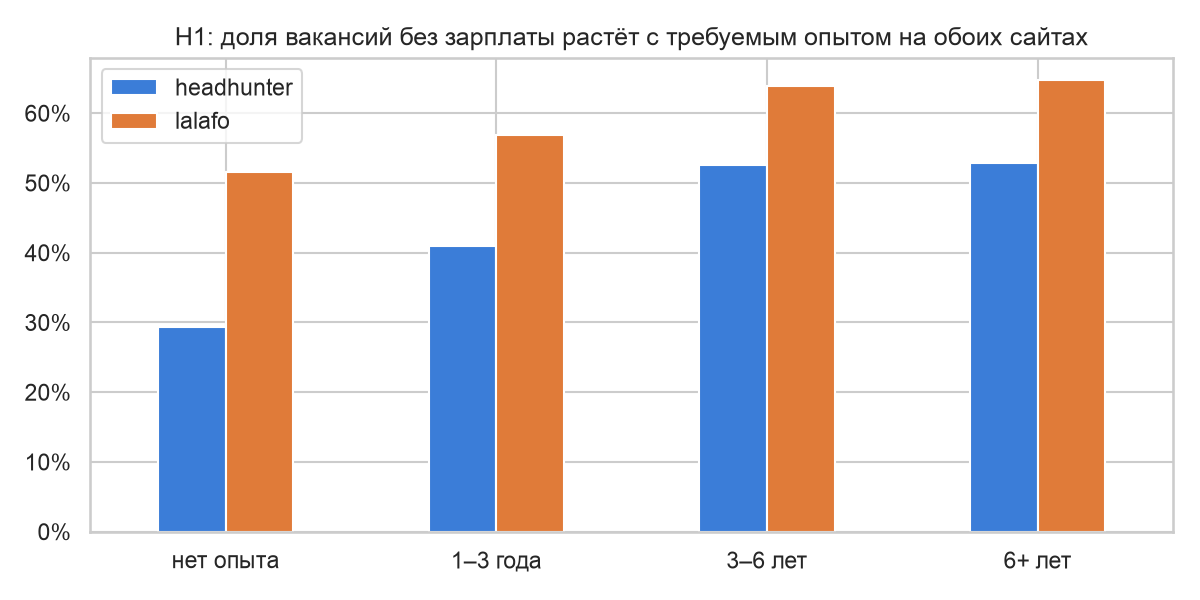

In [2]:
display(Image(FIG + "05_h1.png", width=650))

## 2. Что влияет на зарплату: проверенные различия

Каждая точка ниже это разница медиан с 95% доверительным интервалом. Синие различия статистически
значимы, серые не отличимы от случайности.

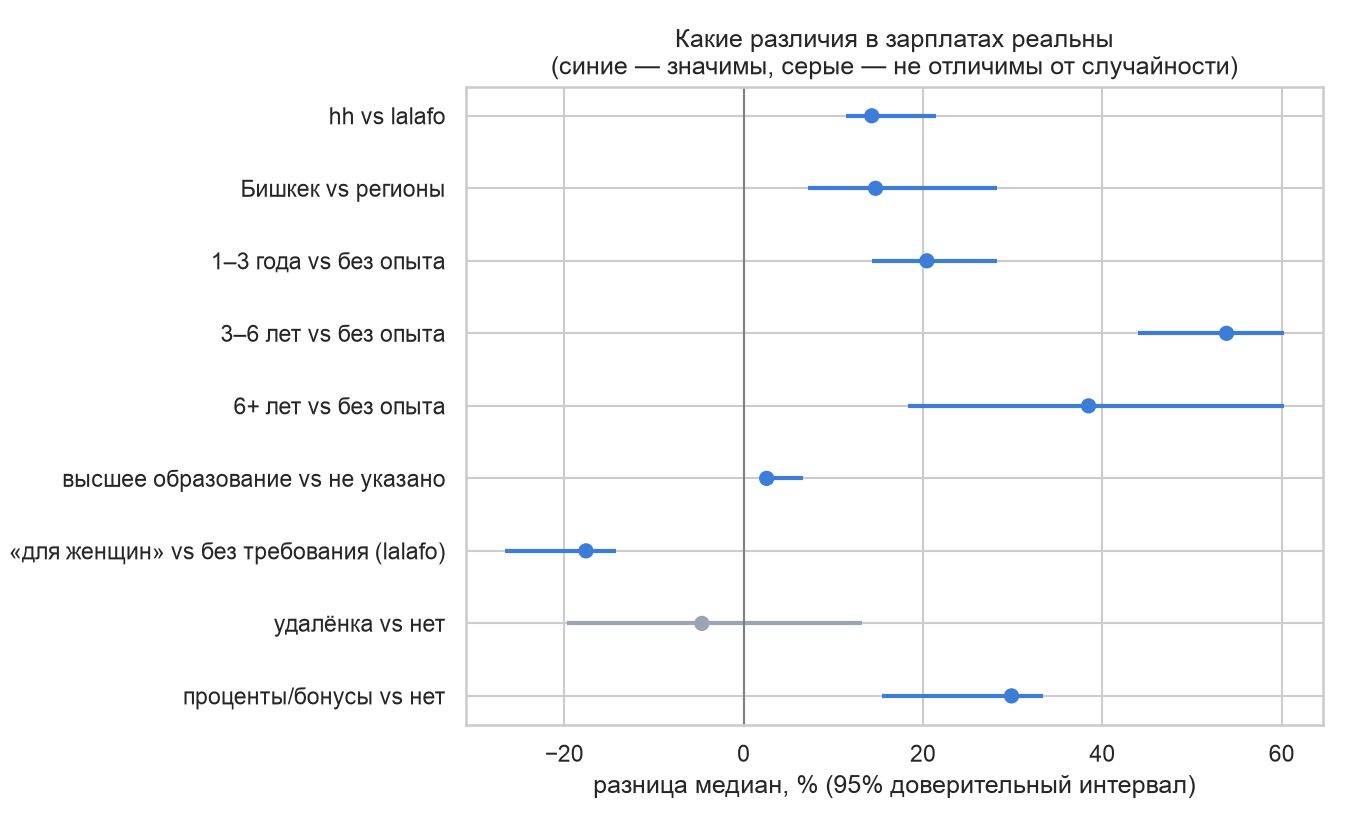

In [3]:
display(Image(FIG + "04_a_forest.png", width=700))

| Фактор | Разница | Надёжность |
|---|---|---|
| Опыт 3–6 лет против «без опыта» | **+54%** | высокая |
| Опыт 1–3 года против «без опыта» | +20% | высокая |
| hh против lalafo | +14% | высокая |
| Бишкек против регионов | +15% (внутри той же сферы около +13%) | средняя, мало региональных данных |
| Оплата с процентами и бонусами | +30% | высокая |
| Требование «для женщин» (lalafo) | −18% в целом, −6% внутри профессии | пограничная внутри профессии |
| Высшее образование | ~+1% внутри сферы | различие меньше 5% доказано (на грани) |
| Удалённая работа | различие не найдено | мало данных (82 вакансии) |

*Подробнее: ноутбуки 04 (A), 05 (H2, H4).*

## 3. Профессия решает больше, чем сфера

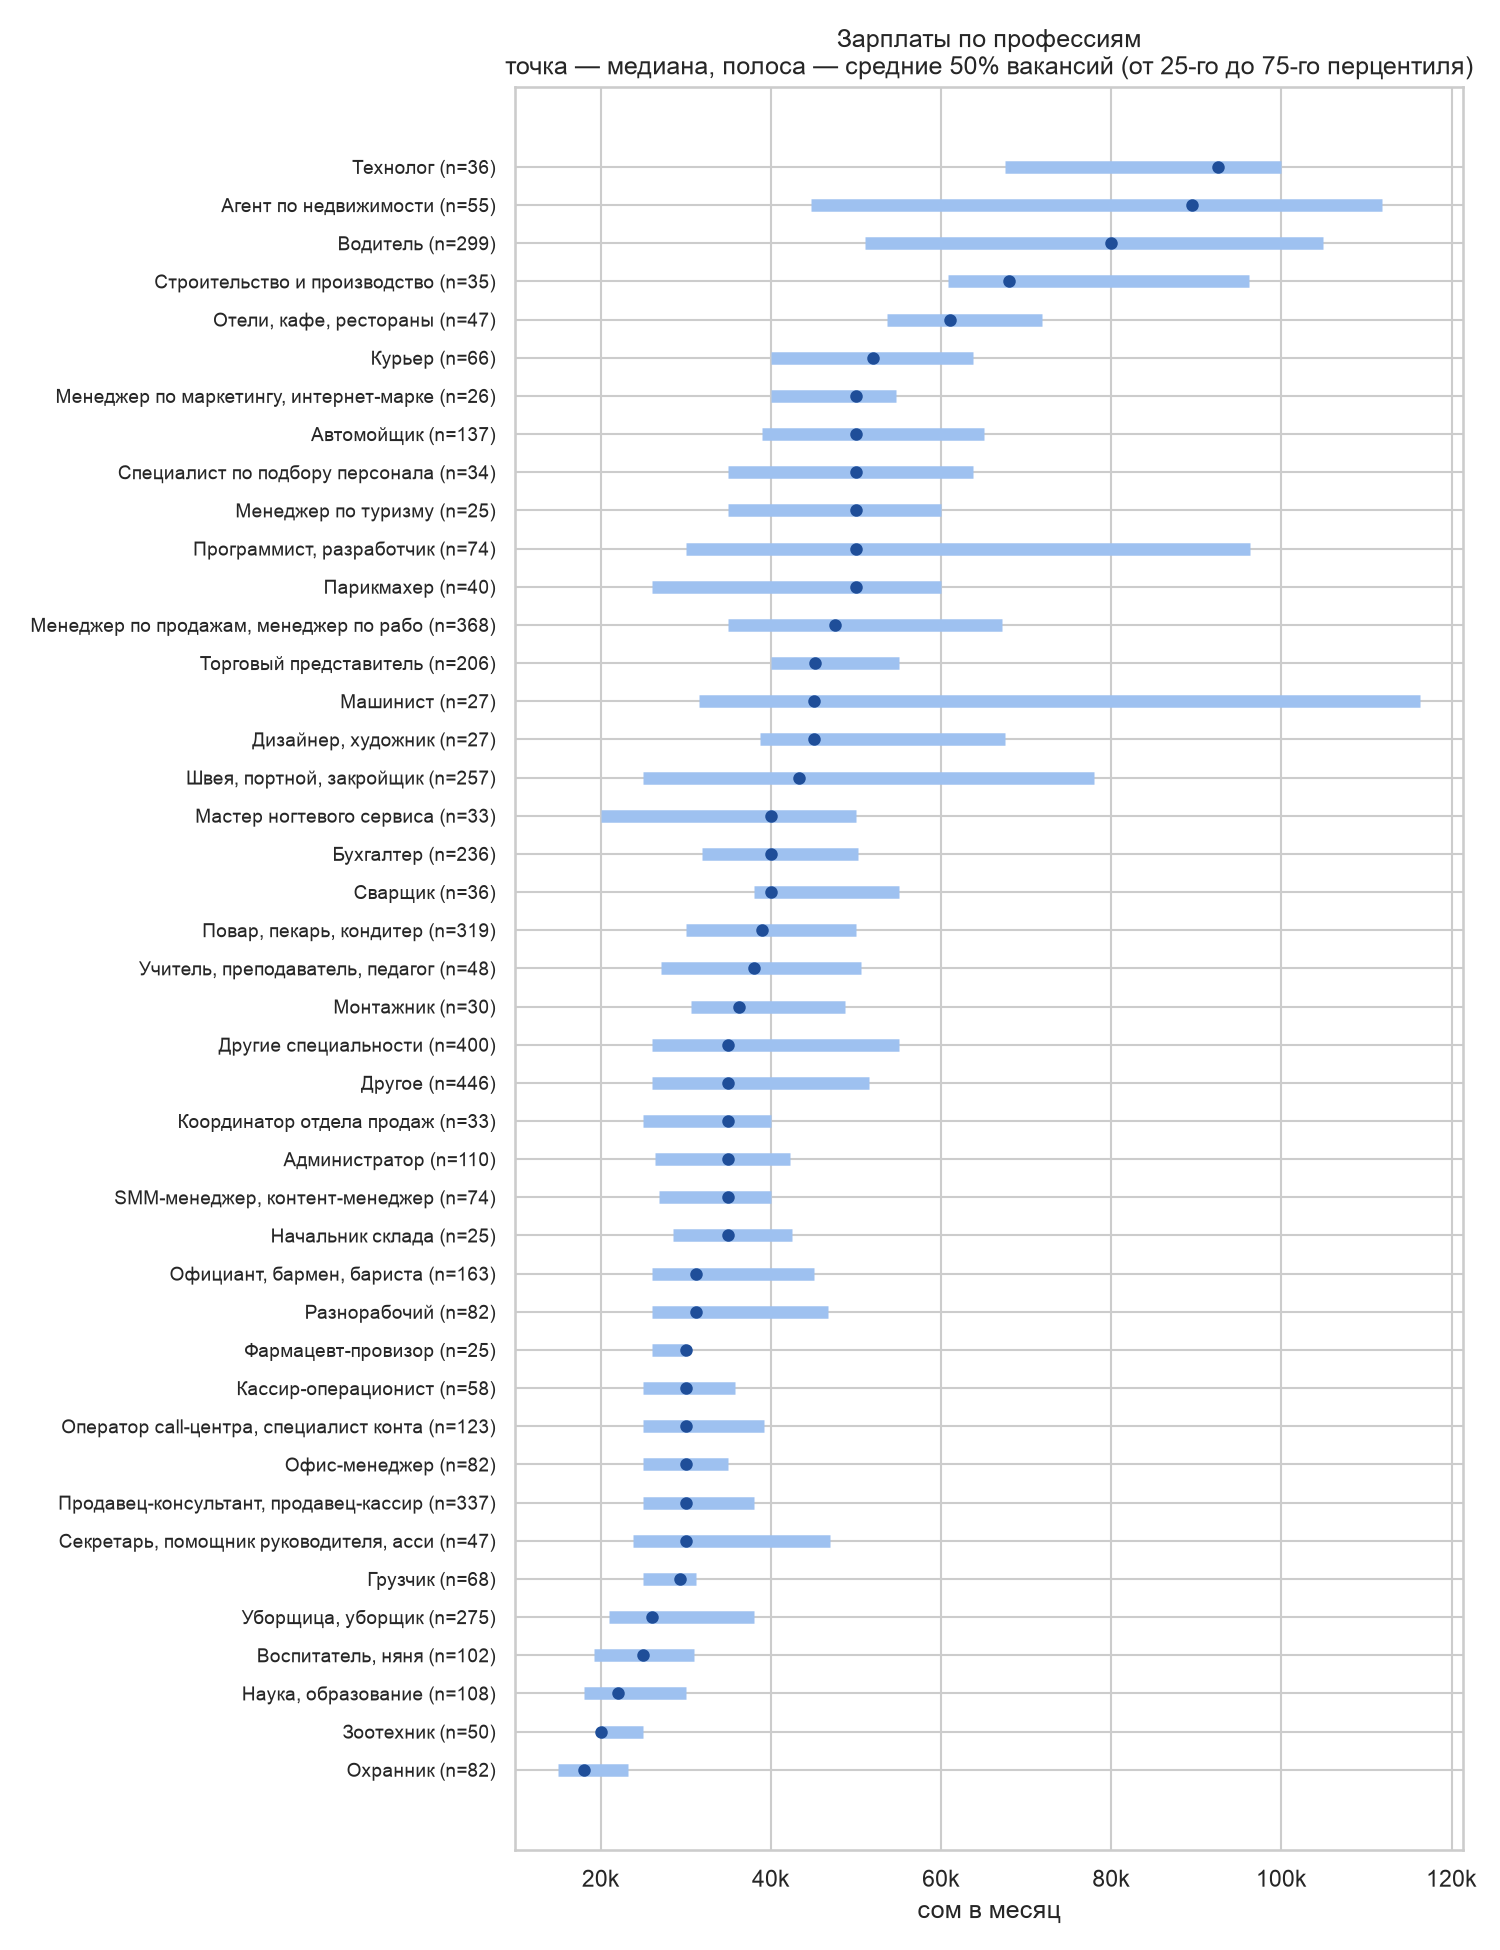

In [4]:
display(Image(FIG + "04_b_roles.png", width=650))

- **Выше всего:** технолог (~93 тыс.), агент по недвижимости (~89 тыс.), водитель (~80 тыс.).
- **Ниже всего:** охранник (~18 тыс.), зоотехник (~20 тыс.), наука и образование (~22 тыс.), няня (~25 тыс.).
- **Самый большой разброс внутри профессии:** машинист, программист, швея. Одна и та же
  профессия стоит от 30 до 100+ тыс. в зависимости от уровня и работодателя.
- **Среди сфер** выше всего платят работа за границей (66 тыс.) и транспорт (60 тыс.),
  ниже всего домашний персонал (20 тыс.) и образование (25 тыс.).

*Подробнее: ноутбуки 03 (п. 2), 04 (B).*

## 4. Навыки: продажи и управление людьми

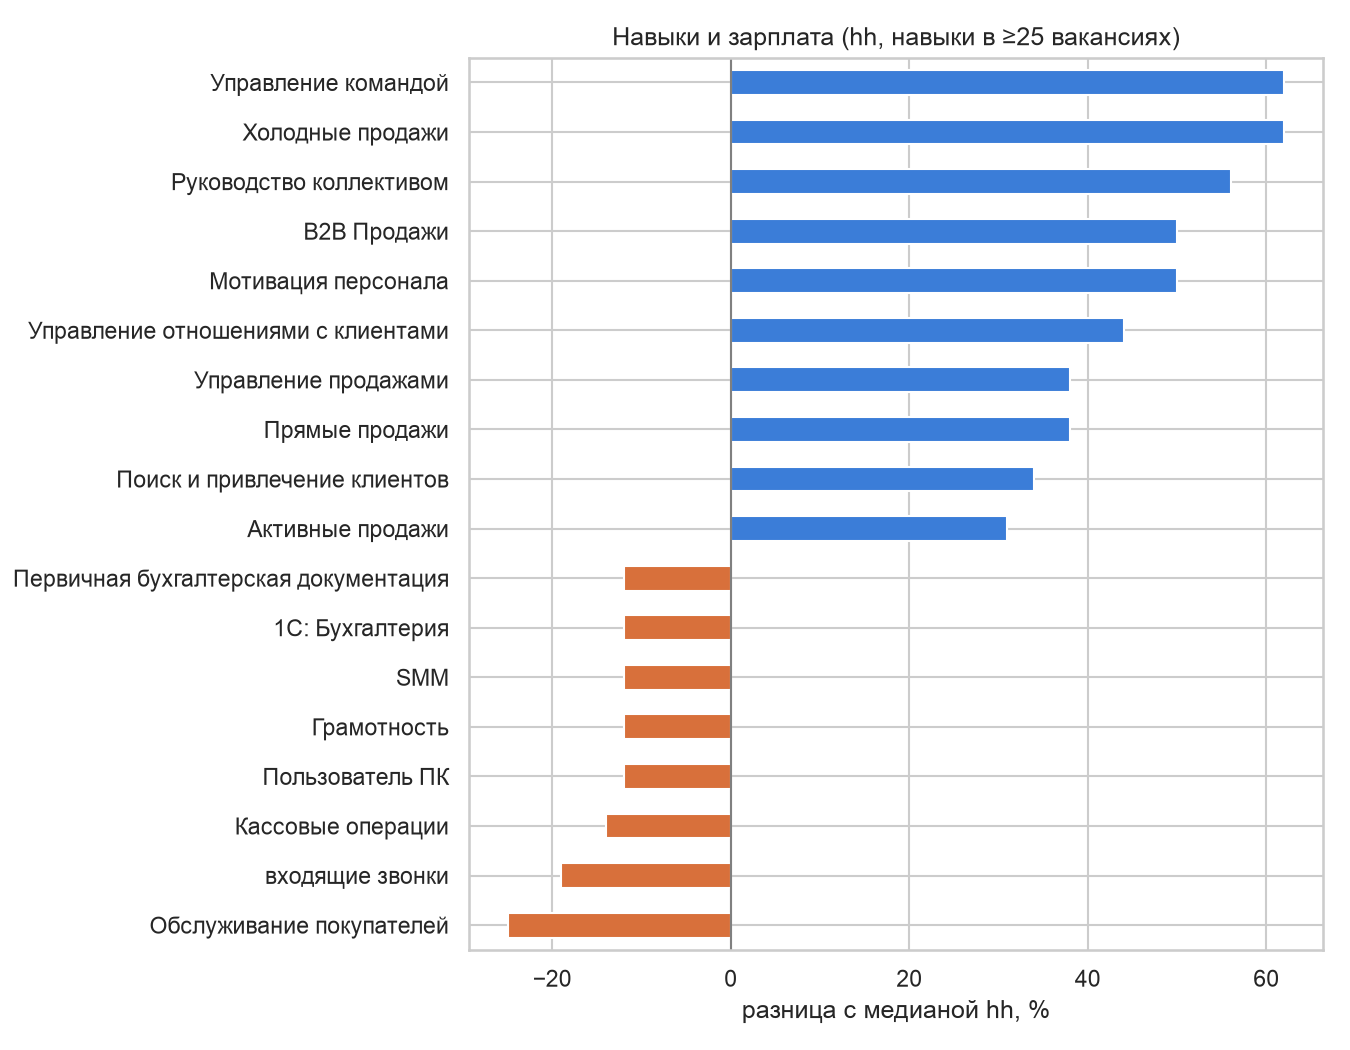

In [5]:
display(Image(FIG + "03_q6_skills.png", width=600))

На hh вакансии с навыками **холодных и B2B-продаж, управления командой** платят на 50–62% выше
медианы hh. Массовые навыки обслуживания (кассовые операции, входящие звонки, обслуживание покупателей)
связаны с зарплатой ниже медианы. Это связь, а не причина: такие навыки встречаются в разных профессиях.

*Подробнее: ноутбук 03 (п. 6).*

## 5. Как устроены объявления

- **18% зарплат указаны за день или за смену** («1 500 сом за выход»); в общепите и гостиницах
  это больше половины. Пересчёт в месяц: 1 500 × 26 дней ≈ 39 000 сом.
- **Зарплаты круглые:** 88% сумм, кратных тысяче, заканчиваются на 0 000 или 5 000.
- **Бонусы почти не связаны с зарплатой:** питание, обучение и «карьерный рост» внутри одной
  сферы на зарплату не влияют; жильё связано с +10% (вахта, работа за рубежом).
- **На lalafo нет диапазонов:** зарплата всегда одно число. Диапазоны есть только на hh
  (в 62% вакансий), верхняя граница обычно в 1,6 раза выше нижней.

*Подробнее: ноутбуки 02, 04 (B, C), 05 (H3).*

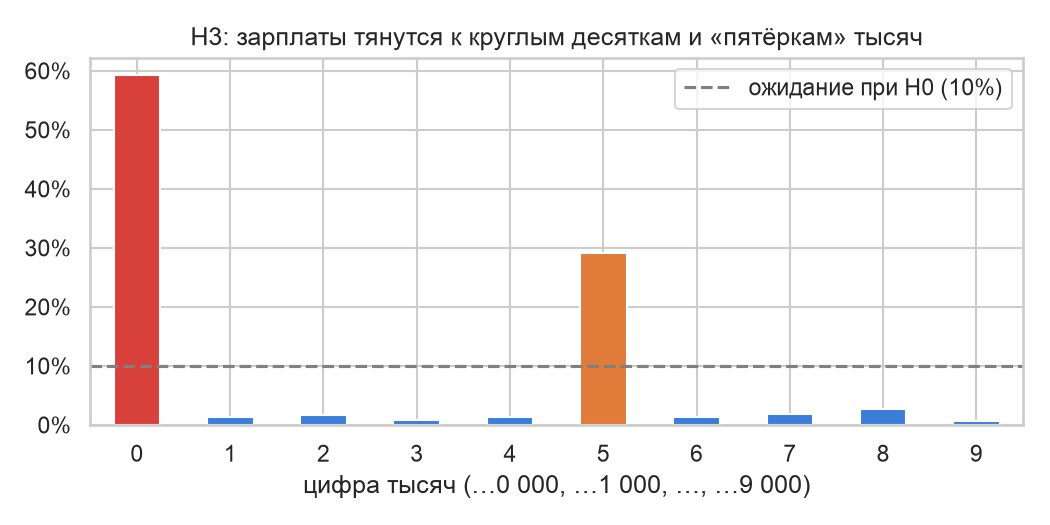

In [6]:
display(Image(FIG + "05_h3.png", width=550))

## 6. Проверка надёжности

- **Устойчивость:** при других допущениях очистки (22 или 30 рабочих дней, другие границы выбросов,
  без пересчитанных ставок) все главные сравнения сохраняют направление. Сильнее всего меняется
  только медиана рынка: от 35 200 до 40 000 сом.
- **Официальная статистика:** в Бишкеке среднее в объявлениях ≈ 48 100 сом против 43 782 по данным
  Нацстаткома (+10%). По стране разрыв больше (+40%), потому что 83% объявлений из Бишкека.
- **Поправка на множественные сравнения:** выводы H1 (скрытие и опыт) и H3 (округление) проходят
  поправку Холма; H2 (пол внутри профессии) и H4 (образование) пограничные.

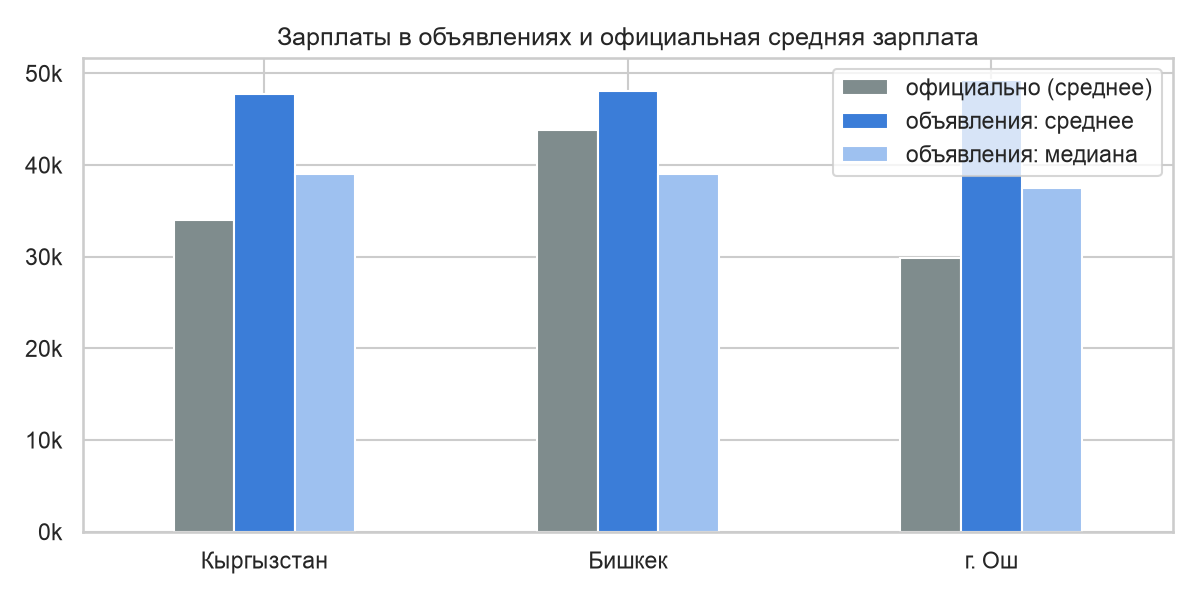

In [7]:
display(Image(FIG + "06_benchmark.png", width=550))

---
## Рекомендации

### Соискателям
1. **Первые годы опыта окупаются сильнее всего.** Переход от «без опыта» к 1–3 годам даёт +20%,
   к 3–6 годам +54%. Ранняя стажировка или первая работа в профессии важнее ожидания «идеальной» вакансии.
2. **Выбор профессии важнее выбора сферы.** Внутри одной сферы зарплаты различаются в разы;
   полезно сравнивать конкретные должности, а не отрасли.
3. **Продажи и управление людьми ценятся выше всего** среди навыков на hh (+50–62%).
4. **Диплом сам по себе не повышает предлагаемую зарплату.** Опыт и навыки весят больше.
5. **Дневную ставку стоит пересчитывать в месяц:** 1 500 сом за выход ≈ 39 000 сом в месяц при 26 днях.
6. **Если зарплата скрыта** (особенно в банках и на позициях для опытных), стоит уточнять её
   на первом этапе и опираться на рыночные диапазоны по профессии.

### Работодателям и HR
1. **Указанная зарплата выделяет вакансию.** Банки скрывают зарплату в 94% вакансий; работодатель,
   который её показывает, заметнее на фоне конкурентов.
2. **Диапазон лучше одного числа.** На hh диапазоны уже в 62% вакансий; типичная ширина 1,6×.
3. **Сверяйте предложение с медианой профессии**, а не сферы: разброс внутри сферы слишком велик.
4. **Требование высшего образования не сопровождается более высокой зарплатой** (~+1%).
   Если диплом не нужен для работы, требование сужает круг кандидатов без пользы.
5. **Требование к полу встречается в 13% объявлений lalafo** и почти всегда в низкооплачиваемых
   профессиях. Оно сужает круг кандидатов.

---
## Ограничения

- **Это объявления, а не реальные зарплаты:** суммы предлагаются, а не выплачиваются.
- **Не весь рынок:** только hh.kg и lalafo.kg; нет госвакансий, Telegram-каналов и найма через знакомых.
  83% объявлений из Бишкека, поэтому выводы по регионам менее надёжны.
- **Снимок времени:** 69% объявлений за февраль–март 2024; часть объявлений lalafo старше.
- **Только 46% вакансий с зарплатой,** и эта половина не случайна (см. п. 1).
- **Текстовые правила** (дневная ставка, образование, пол) вручную не проверялись. Проверка
  устойчивости показывает, что главные выводы от этих допущений не зависят.
- **Все различия это связи, а не причины.**

---
## Карта проекта

| Ноутбук | Содержание |
|---|---|
| 01_overview | структура данных, пропуски, период, первичный обзор |
| 02_cleaning | очистка: резюме, дубликаты, валюты, дневные ставки, выбросы, признаки; журнал решений |
| 03_eda | 10 вопросов о рынке: сферы, опыт, регионы, скрытые зарплаты, навыки, образование, пол |
| 04_deep_dive | доверительные интервалы, профессии, текст объявлений, бонусы, работодатели |
| 05_hypotheses | 5 гипотез: перестановочный тест, TOST, хи-квадрат, поправка Холма; разбор IT |
| 06_validation | устойчивость к допущениям, сравнение с официальной статистикой |

**Порядок запуска:** 02 → 03 → 04 → 05 → 06 → 00 (ноутбук 02 создаёт `vacancies_clean.csv`,
остальные строят графики, которые показывает этот ноутбук).

**Следующий шаг:** ML-модель, которая оценивает скрытые зарплаты (отдельный репозиторий
`kg-salary-prediction`, использует `data/processed/vacancies_clean.csv`).

**Источники официальных данных:** Нацстатком КР через economist.kg:
[средняя зарплата, январь–март 2024](https://economist.kg/dengi/2024/05/14/za-ghod-zarplaty-v-kr-vyrosli-na-3-4-tysiachi-somov/),
[зарплаты по регионам, январь–сентябрь 2024](https://economist.kg/dengi/2024/11/27/bishkiek-i-issyk-kulskaia-oblast-lidiruiut-po-urovniu-sriednikh-zarplat-v-kyrghyzstanie/);
курсы валют НБКР на 14.03.2024:
[economist.kg](https://economist.kg/dengi/2024/03/13/poslie-intiervientsii-nbkr-dollar-i-ievro-vyrosli-v-tsienie-ofitsialnyie-kursy-valiut/).